# MCMC на пальцах

Разберём два алгоритма на одном простом примере. Целевая величина — двумерный вектор $\theta=(x,y)$, распределённый нормально:

$$
(X,Y)\sim\mathcal N\left(
\begin{pmatrix}0\\0\end{pmatrix},
\begin{pmatrix}1&0.8\\0.8&1\end{pmatrix}
\right).
$$

Облако точек вытянуто по диагонали из-за корреляции. В реальных задачах часто известна только ненормированная плотность $\tilde\pi(\theta)$, без константы нормировки

## 0. Подготовка

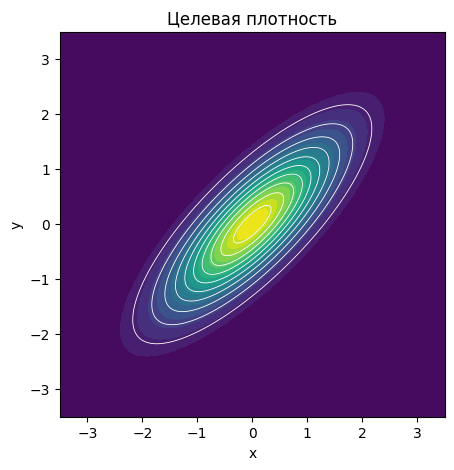

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

rho = 0.8
cov = np.array([[1., rho], [rho, 1.]])
cov_inv = np.linalg.inv(cov)
def log_target(z):
    # Логарифм ненормированной плотности: нормирующая константа опущена.
    z = np.asarray(z)
    return -0.5 * z @ cov_inv @ z

target = multivariate_normal(mean=[0, 0], cov=cov)
grid = np.linspace(-3.5, 3.5, 160)
X, Y = np.meshgrid(grid, grid)
Z = target.pdf(np.dstack((X, Y)))
fig, ax = plt.subplots(figsize=(6, 5))
ax.contourf(X, Y, Z, levels=18, cmap="viridis")
ax.contour(X, Y, Z, levels=10, colors="white", linewidths=.6)
ax.set(xlabel="x", ylabel="y", title="Целевая плотность")
ax.set_aspect("equal")
plt.show()

## 1. Metropolis–Hastings

Из текущей точки $z_t$ предлагаем новую:

$$
z^\star=z_t+\varepsilon,\qquad \varepsilon\sim\mathcal N(0,s^2I).
$$

Предложение симметрично, поэтому вероятность принятия:

$$
\alpha=\min\left(1,\frac{\tilde\pi(z^\star)}{\tilde\pi(z_t)}\right).
$$

Если $u\sim U(0,1)$ и $u<\alpha$, принимаем предложение. Иначе остаёмся в текущей точке. Неизвестная нормирующая константа сокращается в отношении плотностей:

$$
\frac{\pi(z^\star)}{\pi(z_t)}
=\frac{\tilde\pi(z^\star)/C}{\tilde\pi(z_t)/C}
=\frac{\tilde\pi(z^\star)}{\tilde\pi(z_t)}.
$$

В коде сравниваем логарифмы, чтобы избежать численного переполнения/потери точности.

In [2]:
def metropolis_hastings(n_steps=30000, proposal_sd=0.7, seed=10):
    rng = np.random.default_rng(seed)
    chain = np.zeros((n_steps, 2))
    accepted = np.zeros(n_steps, dtype=bool)
    current = np.array([-2.5, 2.5])
    lp = log_target(current)
    for t in range(n_steps):
        proposal = current + rng.normal(0, proposal_sd, size=2)
        proposal_lp = log_target(proposal)
        log_alpha = min(0., proposal_lp - lp)
        if np.log(rng.uniform()) < log_alpha:
            current, lp = proposal, proposal_lp
            accepted[t] = True
        chain[t] = current
    return chain, accepted

mh_chain, mh_accepted = metropolis_hastings()
burn = 2000
mh = mh_chain[burn:]
print(f"Доля принятых предложений: {mh_accepted.mean():.3f}")
print("Среднее после burn-in:", mh.mean(axis=0))
print("Оценка ковариации:\n", np.cov(mh.T))

Доля принятых предложений: 0.530
Среднее после burn-in: [0.0063774  0.00098242]
Оценка ковариации:
 [[1.03546055 0.83326774]
 [0.83326774 1.03034618]]


### 1.1. Как цепочка перемещается по пространству

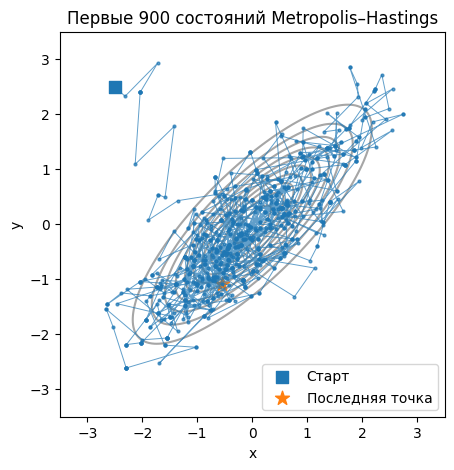

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.contour(X, Y, Z, levels=12, colors="gray", alpha=.7)
ax.plot(mh_chain[:900, 0], mh_chain[:900, 1], "-o",
        markersize=2, linewidth=.7, alpha=.7)
ax.scatter(*mh_chain[0], marker="s", s=65, label="Старт")
ax.scatter(*mh_chain[899], marker="*", s=110, label="Последняя точка")
ax.set(xlabel="x", ylabel="y", title="Первые 900 состояний Metropolis–Hastings")
ax.legend()
ax.set_aspect("equal")
plt.show()

### 1.2. Истинная плотность и выборка алгоритма

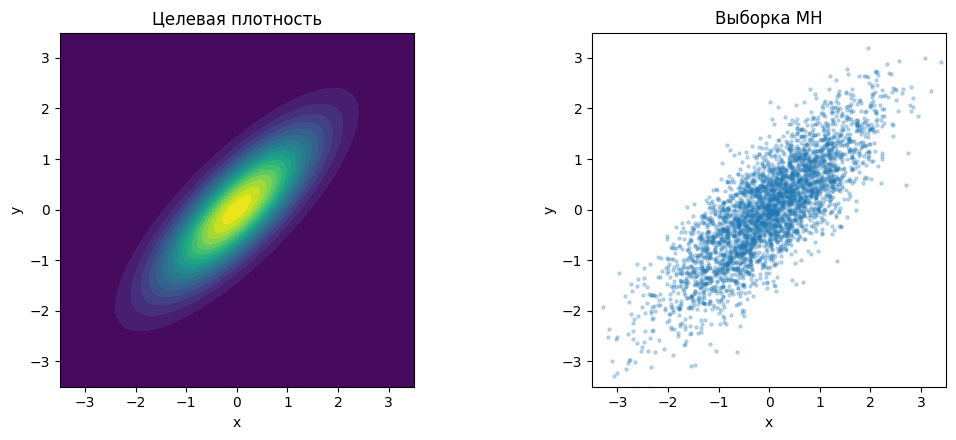

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].contourf(X, Y, Z, levels=18, cmap="viridis")
axes[0].set_title("Целевая плотность")
axes[1].scatter(mh[::8, 0], mh[::8, 1], s=5, alpha=.25)
axes[1].set_title("Выборка MH")
for ax in axes:
    ax.set(xlabel="x", ylabel="y", xlim=(-3.5, 3.5), ylim=(-3.5, 3.5))
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

### 1.3. Trace plot и автокорреляция

Trace plot — значения координаты по итерациям. Сильная зависимость соседних состояний означает, что 30 000 шагов — это не 30 000 независимых наблюдений.

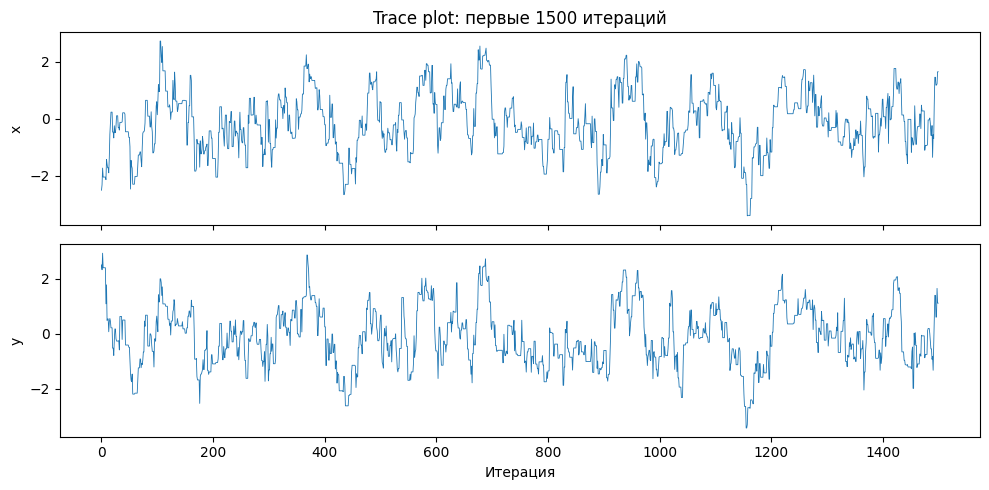

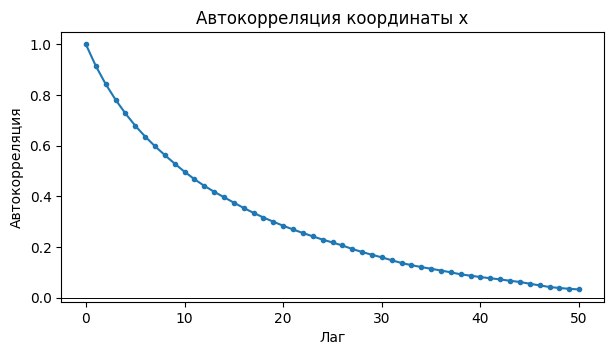

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(mh_chain[:1500, 0], lw=.6); axes[0].set_ylabel("x")
axes[0].set_title("Trace plot: первые 1500 итераций")
axes[1].plot(mh_chain[:1500, 1], lw=.6); axes[1].set_ylabel("y")
axes[1].set_xlabel("Итерация")
plt.tight_layout(); plt.show()

def autocorrelation(x, max_lag=50):
    x = np.asarray(x) - np.mean(x)
    c = np.correlate(x, x, mode="full")[len(x)-1:]
    return c[:max_lag+1] / c[0]

plt.figure(figsize=(7, 3.5))
plt.plot(range(51), autocorrelation(mh[:, 0]), marker="o", ms=3)
plt.axhline(0, color="black", lw=.7)
plt.xlabel("Лаг"); plt.ylabel("Автокорреляция")
plt.title("Автокорреляция координаты x"); plt.show()

### 1.4. Размер случайного шага

Слишком маленький шаг обычно часто принимается, но цепь перемещается медленно. Слишком большой — часто отклоняется. Нужен компромисс; одна только доля принятия не гарантирует хорошего перемешивания.

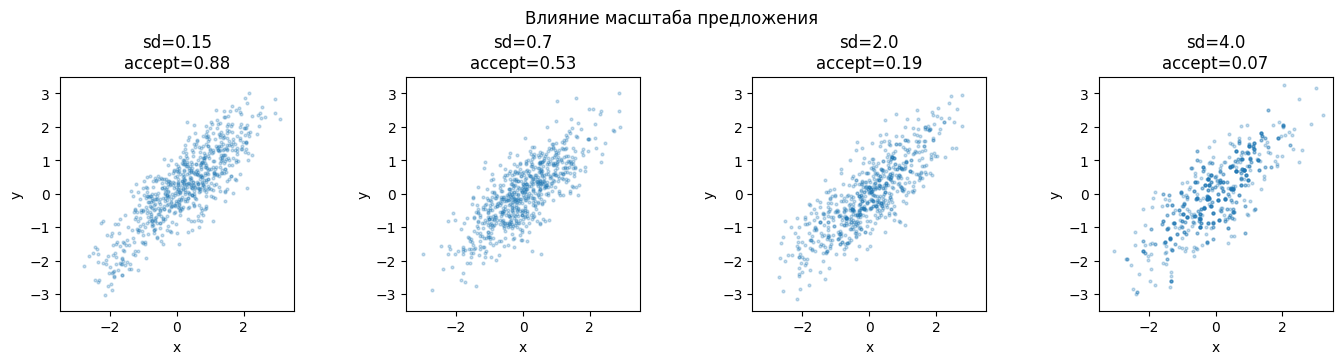

In [6]:
scales = [0.15, 0.7, 2.0, 4.0]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, scale in zip(axes, scales):
    c, a = metropolis_hastings(n_steps=8000, proposal_sd=scale, seed=123)
    s = c[1000:]
    ax.scatter(s[::10, 0], s[::10, 1], s=4, alpha=.25)
    ax.set_title(f"sd={scale}\naccept={a.mean():.2f}")
    ax.set(xlim=(-3.5, 3.5), ylim=(-3.5, 3.5), xlabel="x", ylabel="y")
    ax.set_aspect("equal")
plt.suptitle("Влияние масштаба предложения")
plt.tight_layout(); plt.show()

## 2. Gibbs sampling: обновляем координаты по очереди

Вместо двумерного прыжка генерируем координаты из условных распределений:

1. $X_{t+1}\sim p(x\mid Y_t=y_t)$;
2. $Y_{t+1}\sim p(y\mid X_{t+1}=x_{t+1})$.

Для выбранной двумерной нормали:

$$
X\mid Y=y\sim\mathcal N(\rho y,1-\rho^2),\qquad
Y\mid X=x\sim\mathcal N(\rho x,1-\rho^2).
$$

Во втором шаге используется уже обновлённое $x_{t+1}$. Если условные распределения можно легко сэмплировать, отдельный шаг принятия не нужен.

In [7]:
def gibbs_sampler(n_steps=30000, rho=0.8, seed=11):
    rng = np.random.default_rng(seed)
    chain = np.zeros((n_steps, 2))
    x, y = -2.5, 2.5
    conditional_sd = np.sqrt(1 - rho**2)
    for t in range(n_steps):
        x = rng.normal(rho * y, conditional_sd)
        y = rng.normal(rho * x, conditional_sd)  # уже новое x!
        chain[t] = [x, y]
    return chain

gibbs_chain = gibbs_sampler()
gibbs = gibbs_chain[burn:]
print("Среднее после burn-in:", gibbs.mean(axis=0))
print("Оценка ковариации:\n", np.cov(gibbs.T))

Среднее после burn-in: [-0.00237536 -0.00779485]
Оценка ковариации:
 [[1.0095504  0.81014574]
 [0.81014574 1.0099226 ]]


### 2.1. Траектория и выборка Gibbs

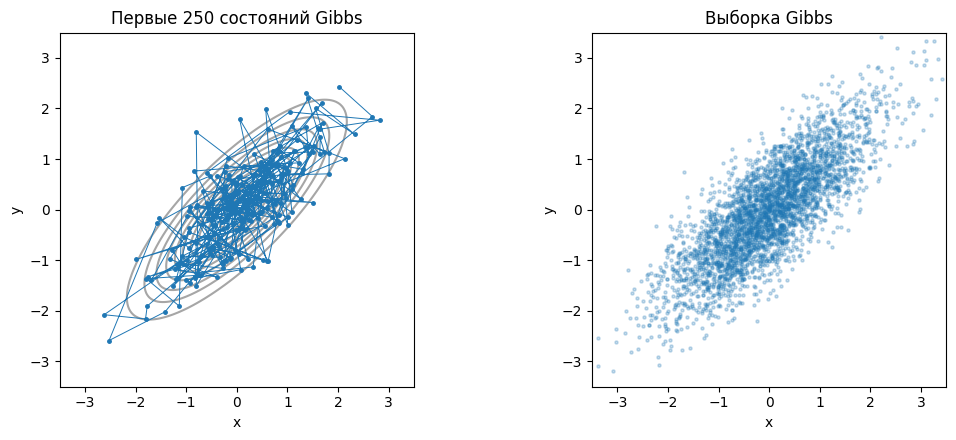

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].contour(X, Y, Z, levels=12, colors="gray", alpha=.7)
axes[0].plot(gibbs_chain[:250, 0], gibbs_chain[:250, 1], "-o",
             ms=2.5, lw=.7)
axes[0].set_title("Первые 250 состояний Gibbs")
axes[1].scatter(gibbs[::8, 0], gibbs[::8, 1], s=5, alpha=.25)
axes[1].set_title("Выборка Gibbs")
for ax in axes:
    ax.set(xlabel="x", ylabel="y", xlim=(-3.5, 3.5), ylim=(-3.5, 3.5))
    ax.set_aspect("equal")
plt.tight_layout(); plt.show()

### 2.2. Сравним trace plots

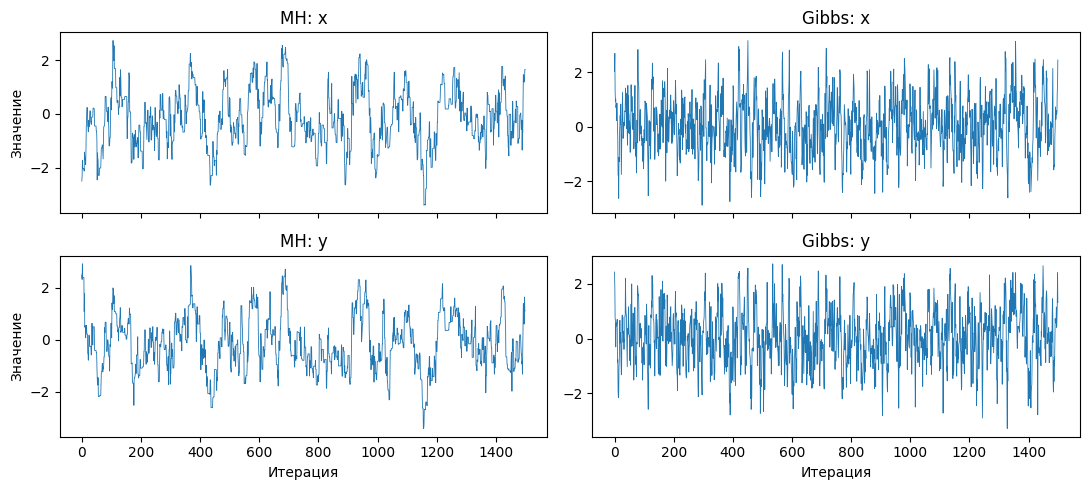

Истинная ковариация:
 [[1.  0.8]
 [0.8 1. ]]

Оценка MH:
 [[1.03546055 0.83326774]
 [0.83326774 1.03034618]]

Оценка Gibbs:
 [[1.0095504  0.81014574]
 [0.81014574 1.0099226 ]]


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharex="col")
axes[0, 0].plot(mh_chain[:1500, 0], lw=.6); axes[0, 0].set_title("MH: x")
axes[1, 0].plot(mh_chain[:1500, 1], lw=.6); axes[1, 0].set_title("MH: y")
axes[0, 1].plot(gibbs_chain[:1500, 0], lw=.6); axes[0, 1].set_title("Gibbs: x")
axes[1, 1].plot(gibbs_chain[:1500, 1], lw=.6); axes[1, 1].set_title("Gibbs: y")
for ax in axes[1, :]: ax.set_xlabel("Итерация")
for ax in axes[:, 0]: ax.set_ylabel("Значение")
plt.tight_layout(); plt.show()

print("Истинная ковариация:\n", cov)
print("\nОценка MH:\n", np.cov(mh.T))
print("\nОценка Gibbs:\n", np.cov(gibbs.T))

Если хотите, то здесь можно позалипать на красивую визуализацию: https://johannesbuchner.github.io/mcmc-demo/app.html#HamiltonianMC,banana